# 04 — V2: train tiếp V1 với lr 1e-4

> Notebook trình bày, **không huấn luyện lại**. Mọi bảng và hình được tính từ file kết quả đã lưu trong `saved/`, chạy lại an toàn trên CPU. Log huấn luyện đã được rút gọn (bỏ thanh tiến độ, giữ mọi kết quả eval); bản đầy đủ nằm trong `ASR/notebooks/local` và `ASR/local/logs`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
S = next(p / 'saved' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'saved/tables').is_dir())
T = S / 'tables'
def js(rel): return json.loads((S / rel).read_text(encoding='utf-8'))
def show_log(name): print((S / 'logs' / name).read_text(encoding='utf-8'))
def history(name): return js(f'runs/{name}_trainer_state.json')['log_history']
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'Baseline 1': '#7E9C9B', 'Baseline 2': '#A9C2C0', 'V1': '#0F4E57', 'V2': '#1A6771', 'V-Final': '#FFB21A'}

**Lý do từ phân tích lỗi V1:** lr 1e-3 làm huấn luyện phân kỳ (loss và eval loss vọt lên quanh bước 700–900, xem `03_V1`).
V2 khởi tạo từ adapter tốt nhất của V1 và train thêm 2 epoch với lr thấp hơn 10 lần; mọi thứ khác giữ nguyên.

In [2]:
print((S / 'configs/V2.yaml').read_text(encoding='utf-8'))

# V2 — continue V1: warm-start from the V1 best adapter (local_v1 checkpoint-2600) with a 10x lower LR.
# V1 at lr 1e-3 diverged around steps 660-900 (loss 0.4 -> 4.6, grad_norm up to 480) and only improved
# once the linear decay brought the LR below ~3e-4; its best DEV-subset WER (0.1339) came at the low-LR end.
# Same data, LoRA shape and DEV subset as V1, so eval_wer curves are directly comparable.
model:
  name: vinai/PhoWhisper-small
  lora:                      # must match the init adapter; also used to load V2/final for evaluation
    r: 32
    alpha: 64
    dropout: 0.05
    target_modules: [q_proj, k_proj, v_proj, out_proj, fc1, fc2]
  init_adapter: local/runs/V1_phowhisper_small_lora/local_v1/final   # relative to ASR/

train:
  epochs: 2
  batch_size: 16
  grad_accum: 2              # effective batch 32
  lr: 1.0e-4
  warmup_ratio: 0.05
  fp16: true
  gradient_checkpointing: true
  eval_steps: 500
  save_steps: 500
  save_total_limit: 2
  logging_steps: 50
  num_workers: 2

**Lệnh đã chạy — huấn luyện V2 (chạy nền, log lưu ra file)** (chép từ `ASR/notebooks/local/08_V2.ipynb`, ô 5; chỉ để xem)

```python
pid = gpu_job_running()
if pid:
    print(f'Đang có job GPU khác (PID {pid}); không khởi chạy thêm. Dùng cell theo dõi bên dưới, hoặc dừng job đó trước.')
else:
    print('Train V2: bắt đầu mới hoặc tiếp tục từ', latest_checkpoint(RUN) or 'bước 0', flush=True)
    run_cli([RUNNER, 'train', EXP, '--run-id', RUN_ID])
    print('Adapter tốt nhất:', FINAL if (FINAL/'adapter_model.safetensors').is_file() else 'chưa có')
```

In [3]:
show_log('V2_train.txt')

===== 20261023_234313_train_v2.log
[INIT] mode=train experiment=V2_phowhisper_small_lora_cont; importing PyTorch/ASR libraries...
{
  "python": "D:\\1.FPT_FALL26\\DPL - Deep Learning\\.venv-asr\\Scripts\\python.exe",
  "cuda": true,
  "versions": {
    "torch": "2.6.0+cu124",
    "transformers": "4.46.3",
    "peft": "0.13.2",
    "accelerate": "1.1.1",
    "datasets": "3.1.0"
  },
  …
}
[MODEL] Loading processor and weights; first use may download model files...
trainable params: 12,976,128 || all params: 254,711,040 || trainable%: 5.0945
[MODEL] Weights loaded.
[DATA] Loading TRAIN parquet and applying duration filters...
Exclude ViMedCSS/train: 10 empty-audio rows (duration <= 0): ['vimedcss:Med_CS-3625-10', 'vimedcss:Med_CS-3625-17', 'vimedcss:Med_CS-3625-19', 'vimedcss:Med_CS-3625-20', 'vimedcss:Med_CS-3625-5', 'vimedcss:Med_CS-3625-9', 'vimedcss:Med_CS-4072_1-1', 'vimedcss:Med_CS-4072_1-15', 'vimedcss:Med_CS-4072_1-17', 'vimedcss:Med_CS-4072_1-8']
[DATA] TRAIN: 29061 clips. Loadi

In [4]:
show_log('V2_dev_eval.txt')

[INIT] mode=eval experiment=V2_phowhisper_small_lora_cont; importing PyTorch/ASR libraries...
{
  "python": "D:\\1.FPT_FALL26\\DPL - Deep Learning\\.venv-asr\\Scripts\\python.exe",
  "cuda": true,
  "versions": {
    "torch": "2.6.0+cu124",
    "transformers": "4.46.3",
    "peft": "0.13.2",
    "accelerate": "1.1.1",
    "datasets": "3.1.0"
  },
  …
}
[MODEL] Loading processor and weights; first use may download model files...
[MODEL] Weights loaded.
Exclude ViMedCSS/dev: 1 empty-audio rows (duration <= 0): ['vimedcss:Med_CS-4072_1-11']
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
5168/5168
{
  "overall_wer": 0.19075641416391187,
  "by_source_wer": {
    "FLEURS": 0.11079848646550888,
    "VIVOS": 0.06157270029673591,
    "ViMedCSS": 0.17285912529656655,
    "VietMed": 0.22189177426374582
  }
}
Elapsed: 

## V1 và V2 trong lúc train (cùng DEV-subset 600 clip)

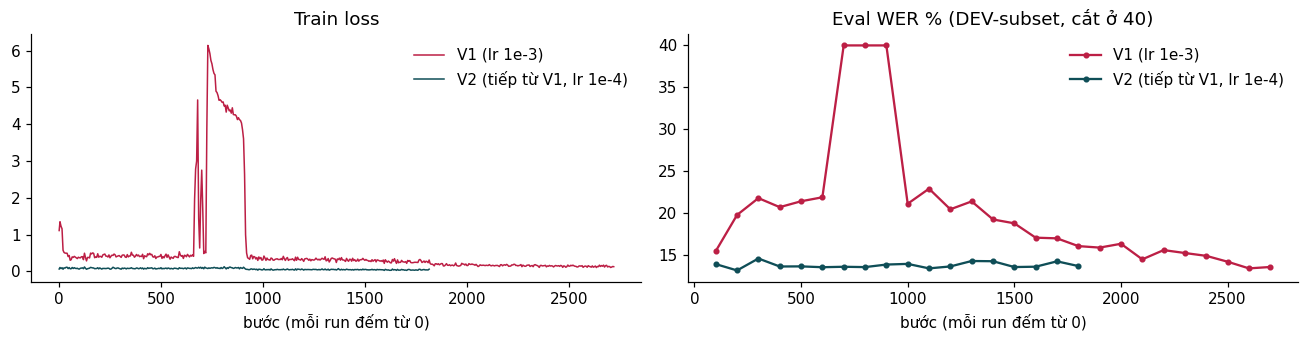

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for name, col, lab in [('V1', '#BC1F45', 'V1 (lr 1e-3)'), ('V2', '#0F4E57', 'V2 (tiếp từ V1, lr 1e-4)')]:
    h = history(name); tr = pd.DataFrame([x for x in h if 'loss' in x and 'step' in x]); ev = pd.DataFrame([x for x in h if 'eval_wer' in x])
    ax[0].plot(tr.step, tr.loss, lw=1, color=col, label=lab); ax[1].plot(ev.step, (100 * ev.eval_wer).clip(upper=40), marker='o', ms=3, color=col, label=lab)
ax[0].set_title('Train loss'); ax[1].set_title('Eval WER % (DEV-subset, cắt ở 40)')
for a in ax: a.set_xlabel('bước (mỗi run đếm từ 0)'); a.legend(frameon=False)
plt.tight_layout(); plt.show()

## Kết quả trên toàn bộ DEV chính thức

In [6]:
def dev_row(name):
    m = js(f'metrics/{name}.json'); o, s = m['overall'], m['by_source']
    return {'WER %': 100 * o['wer'], 'CER %': 100 * o['cer'], 'Recall thuật ngữ %': 100 * o.get('cs_term_recall', float('nan')),
            **{k: 100 * s[k]['wer'] for k in ['ViMedCSS', 'VietMed', 'FLEURS', 'VIVOS']}}
DEV = pd.DataFrame({'V1': dev_row('V1_dev'),
                    'V2': dev_row('V2_dev')}).T
DEV

,WER %,CER %,Recall thuật ngữ %,ViMedCSS,VietMed,FLEURS,VIVOS
V1,18.48,14.36,71.26,16.10,21.80,11.12,6.92
V2,19.08,14.87,72.59,17.29,22.19,11.08,6.16


In [7]:
(DEV.loc['V2'] - DEV.loc['V1']).round(2).rename('V2 − V1 (điểm %)')

WER %                 0.60
CER %                 0.51
Recall thuật ngữ %    1.32
ViMedCSS              1.19
VietMed               0.39
FLEURS               -0.04
VIVOS                -0.77
Name: V2 − V1 (điểm %), dtype: float64

**Nhận xét:** V2 không cải thiện WER tổng; train tiếp với lr thấp không sửa được hậu quả của đợt phân kỳ. Vì vậy V-Final huấn luyện lại từ đầu với lr 1e-4 và xử lý thêm các nguyên nhân lỗi khác.